In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '4' #Evita el aviso de KMeans en Windows; debe ir antes de importar numpy

import numpy as np
import pandas as pd #Permite mostrar tablas como si fuesen de excel
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=12)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

<h1>Aplicación 2: Roles de combate de los Pokémon con K-means</h1>

<h1>Problema</h1>
<p>Los jugadores hablan de "roles" (tanques, atacantes rápidos, muros...), pero el juego no los define. Se intentará averiguar si con K-means se puede descubrir esos roles solo con los números de cada Pokémon.</p>
<ul>
  <li>Cada Pokémon es un punto en 6 dimensiones (sus 6 estadísticas).</li>
  <li>K-means junta a los que tienen estadísticas parecidas.</li>
  <li>El centroide de cada grupo describe al "Pokémon típico" de ese rol.</li>
  <li>Nadie le dice a K-means qué roles existen.</li>
</ul>

<h1>Dataset</h1>
<p>https://github.com/lgreski/pokemonData (basado en Bulbapedia, generaciones 1 a 9)</p>
<ul>
  <li><b>HP:</b> puntos de vida</li>
  <li><b>Attack:</b> ataque físico</li>
  <li><b>Defense:</b> defensa física</li>
  <li><b>Sp. Atk:</b> ataque especial</li>
  <li><b>Sp. Def:</b> defensa especial</li>
  <li><b>Speed:</b> velocidad (quién ataca primero)</li>
  <br>
  <li><b>Total:</b> suma de las 6 estadísticas</li>
  <li><b>Form:</b> forma alternativa del Pokémon (vacío si es la forma normal)</li>
  <li><b>Type1, Type2:</b> tipos del Pokémon (Fuego, Agua, Roca...). No se usan para agrupar, solo para validar al final.</li>
</ul>

In [3]:
df = pd.read_csv('datos/pokemon.csv')

In [4]:
df.head()

,ID,Name,Form,Type1,Type2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
0,1,Bulbasaur,,Grass,Poison,318,45,49,49,65,65,45,1
1,2,Ivysaur,,Grass,Poison,405,60,62,63,80,80,60,1
2,3,Venusaur,,Grass,Poison,525,80,82,83,100,100,80,1
3,4,Charmander,,Fire,,309,39,52,43,60,50,65,1
4,5,Charmeleon,,Fire,,405,58,64,58,80,65,80,1


In [5]:
df.shape

(1215, 13)

<p>Algunas especies aparecen en varias filas porque tienen formas alternativas (por ejemplo, las formas de Giratina o de Deoxys). Todas las filas de una misma especie comparten el mismo ID, así que se deja solo la primera de cada ID, que en el archivo es la forma normal. Así queda un Pokémon por especie.</p>

In [6]:
df = df.drop_duplicates('ID') #Deja solo la primera fila de cada especie (su forma normal)
df.shape

(1025, 13)

In [7]:
stats = ['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed']

df[stats].isnull().sum()

HP         0
Attack     0
Defense    0
Sp. Atk    0
Sp. Def    0
Speed      0
dtype: int64

<h1>Preparación de los datos</h1>
<p>Un Legendario tiene todas sus stats altas y un Pokémon sin evolucionar las tiene todas bajas. Si se agrupa con las stats tal cual, K-means separa sobre todo fuertes contra débiles, no roles.</p>
<p>Para encontrar roles se usa el perfil de cada Pokémon: qué fracción de su total tiene en cada stat.</p>

$$p_{ij} = \frac{x_{ij}}{\sum_{j=1}^{6} x_{ij}}$$
<ul>
  <li>i: el Pokémon (fila).</li>
  <li>j: la stat (HP, Attack, Defense, Sp. Atk, Sp. Def o Speed).</li>
  <li>x<sub>ij</sub>: valor de la stat j del Pokémon i.</li>
  <li>El denominador es el total del Pokémon i (la suma de sus 6 stats).</li>
  <li>p<sub>ij</sub>: fracción de su total que el Pokémon i tiene en la stat j. Cada fila suma 1.</li>
</ul>

<p>Así, un Pokémon con mucho de su total en Velocidad es "rápido" sin importar si es fuerte o débil.</p>
<p>Observación: aquí no hace falta <code>StandardScaler</code>, porque las 6 columnas ya están en la misma escala (fracción del total) y así los centroides se leen directo.</p>

In [8]:
X = df[stats].values
X = X / X.sum(axis=1)[:, np.newaxis] #Divide cada fila entre su total; np.newaxis convierte el total en columna para poder dividir
X.shape

(1025, 6)

In [9]:
pd.DataFrame(X[:5], columns=stats).round(3) #Perfil de los primeros 5 Pokémon; cada fila suma 1

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
0,0.142,0.154,0.154,0.204,0.204,0.142
1,0.148,0.153,0.156,0.198,0.198,0.148
2,0.152,0.156,0.158,0.190,0.190,0.152
3,0.126,0.168,0.139,0.194,0.162,0.210
4,0.143,0.158,0.143,0.198,0.160,0.198


In [10]:
X[(df['Name'] == 'Pikachu').values].round(3) #Pikachu tiene 28% de su total en velocidad

array([[0.109, 0.172, 0.125, 0.156, 0.156, 0.281]])

<h1>Número óptimo de clusters</h1>
<p>Se usan los dos métodos del inciso 3 (codo y silueta), ahora con las funciones de Scikit-Learn:</p>
<ul>
  <li>Método del codo: inercia (<code>inertia_</code>) para cada k.</li>
  <li>Coeficiente de silueta: <code>silhouette_score</code>, de −1 a 1; más alto es mejor.</li>
</ul>

In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [12]:
ks = range(2, 11)
inercias = []
siluetas = []

for k in ks:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inercias.append(kmeans.inertia_)
    siluetas.append(silhouette_score(X, kmeans.labels_))

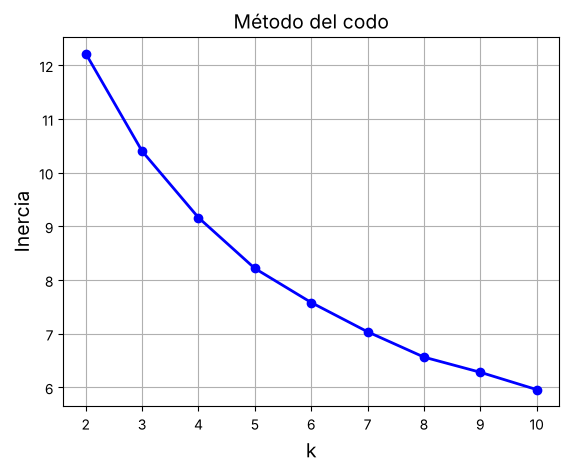

In [13]:
plt.plot(ks, inercias, 'b-o', linewidth=2)
plt.xlabel('k')
plt.ylabel('Inercia')
plt.title('Método del codo')
plt.grid(True)
plt.show()

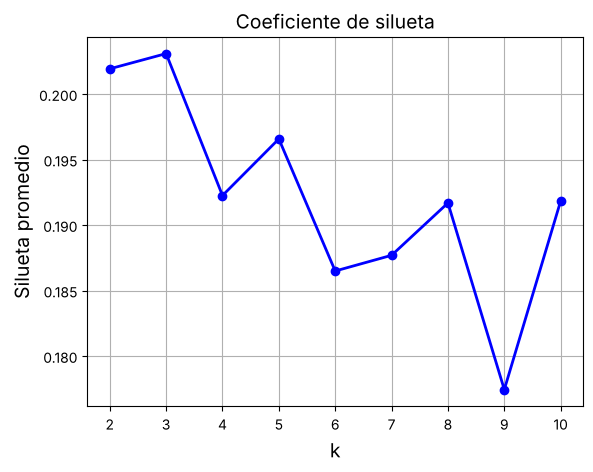

In [14]:
plt.plot(ks, siluetas, 'b-o', linewidth=2)
plt.xlabel('k')
plt.ylabel('Silueta promedio')
plt.title('Coeficiente de silueta')
plt.grid(True)
plt.show()

In [15]:
for i in range(len(ks)):
    print(f'k = {ks[i]:2} -> inercia = {inercias[i]:.3f}, silueta = {siluetas[i]:.3f}')

k =  2 -> inercia = 12.218, silueta = 0.202
k =  3 -> inercia = 10.399, silueta = 0.203
k =  4 -> inercia = 9.161, silueta = 0.192
k =  5 -> inercia = 8.216, silueta = 0.197
k =  6 -> inercia = 7.581, silueta = 0.186
k =  7 -> inercia = 7.036, silueta = 0.188
k =  8 -> inercia = 6.564, silueta = 0.192
k =  9 -> inercia = 6.281, silueta = 0.177
k = 10 -> inercia = 5.959, silueta = 0.192


<p>Observación: el codo es suave, no hay un k claramente "correcto". La silueta más alta sale en k = 3 (0.203), pero las diferencias con k = 2 y k = 5 son mínimas (milésimas), y en k = 5 hay un pico local (es mayor que en 4 y en 6). Con 2 o 3 grupos solo se separarían estilos muy generales; con 5 cada grupo tiene una interpretación clara. Por eso se usa k = 5.</p>
<p>La silueta es baja (alrededor de 0.2): los grupos se traslapan. Es esperable, porque muchos Pokémon son "equilibrados" y quedan en la frontera entre dos roles.</p>

<h1>K-means con Scikit-Learn (k = 5)</h1>

In [16]:
k = 5
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)

In [17]:
centros = pd.DataFrame(kmeans.cluster_centers_ * 100, columns=stats) #Centroides en % del total
centros.round(1)

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
0,15.7,14.2,15.9,20.1,19.5,14.6
1,16.8,22.4,17.3,13.8,14.6,14.9
2,28.1,16.3,14.8,14.8,16.0,10.1
3,14.6,17.4,27.6,12.9,18.6,8.9
4,14.5,17.3,13.5,17.0,14.4,23.3


<h2>Nombre de cada grupo</h2>
<p>K-means numera los grupos en un orden arbitrario. Para nombrarlos, se busca en qué stat destaca cada centroide comparado con el Pokémon promedio.</p>

In [18]:
promedio = X.mean(axis=0) * 100 #Perfil del Pokémon promedio
diferencia = centros - promedio #Puntos porcentuales arriba (+) o abajo (-) del promedio
diferencia.round(1)

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
0,-0.8,-3.8,-1.0,3.8,3.1,-1.2
1,0.3,4.4,0.4,-2.4,-1.7,-0.9
2,11.6,-1.7,-2.2,-1.4,-0.4,-5.8
3,-1.9,-0.6,10.6,-3.3,2.2,-6.9
4,-1.9,-0.7,-3.5,0.7,-2.0,7.4


In [19]:
nombre_por_stat = {'HP': 'Mucha vida', 'Attack': 'Atacantes físicos', 'Defense': 'Defensivos',
                   'Sp. Atk': 'Especiales', 'Sp. Def': 'Especiales', 'Speed': 'Rápidos'}

nombres = []
for g in range(k):
    stat_mayor = stats[np.argmax(diferencia.values[g])] #np.argmax regresa la posición del valor más alto
    nombre = nombre_por_stat[stat_mayor]
    if nombre in nombres: #Si dos grupos destacan en lo mismo, se les distingue con un número
        nombre = f'{nombre} 2'
    nombres.append(nombre)

nombres

['Especiales', 'Atacantes físicos', 'Mucha vida', 'Defensivos', 'Rápidos']

In [20]:
df['Rol'] = [nombres[g] for g in kmeans.labels_] #labels_ dice a qué grupo pertenece cada Pokémon

for rol in nombres:
    cantidad = (df['Rol'] == rol).sum()
    print(f'{rol:18} -> {cantidad} Pokémon')

Especiales         -> 277 Pokémon
Atacantes físicos  -> 321 Pokémon
Mucha vida         -> 70 Pokémon
Defensivos         -> 111 Pokémon
Rápidos            -> 246 Pokémon


<h2>Perfil de cada rol</h2>
<p>Cada celda dice cuántos puntos porcentuales está el centroide por arriba (rojo) o por debajo (azul) del Pokémon promedio en esa stat.</p>

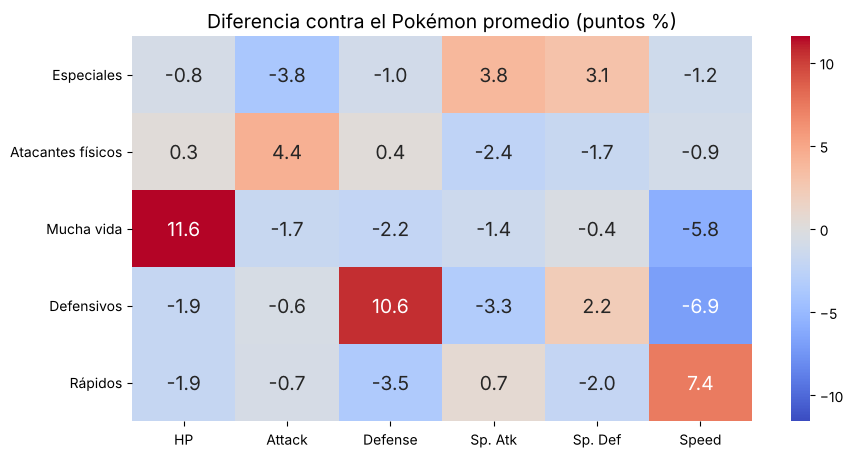

In [21]:
diferencia.index = nombres
limite = np.abs(diferencia.values).max() #Para que el 0 quede en el color neutro

plt.figure(figsize=(10, 5))
sns.heatmap(diferencia, cmap='coolwarm', annot=True, fmt='.1f', vmin=-limite, vmax=limite)
plt.title('Diferencia contra el Pokémon promedio (puntos %)')
plt.show()

<h2>Ejemplos de Pokémon conocidos</h2>

In [22]:
famosos = ['Pikachu', 'Snorlax', 'Shuckle', 'Blissey', 'Chansey', 'Alakazam', 'Machamp', 'Ninjask', 'Steelix', 'Gengar', 'Mewtwo']

for nombre in famosos:
    rol = df[df['Name'] == nombre]['Rol'].values[0]
    print(f'{nombre:10} -> {rol}')

Pikachu    -> Rápidos
Snorlax    -> Mucha vida
Shuckle    -> Defensivos
Blissey    -> Mucha vida
Chansey    -> Mucha vida
Alakazam   -> Rápidos
Machamp    -> Atacantes físicos
Ninjask    -> Rápidos
Steelix    -> Defensivos
Gengar     -> Rápidos
Mewtwo     -> Rápidos


<h2>Validación con los tipos</h2>
<p>K-means nunca vio el tipo de los Pokémon. Si los grupos tienen sentido, ciertos tipos deberían caer mucho en el rol que se les asocia en el juego, por ejemplo Roca y Acero en los defensivos, o Psíquico en los especiales.</p>
<p>Cada fila dice en qué rol cayeron los Pokémon de ese tipo (en %). La última fila es el reparto de todos los Pokémon, para comparar.</p>

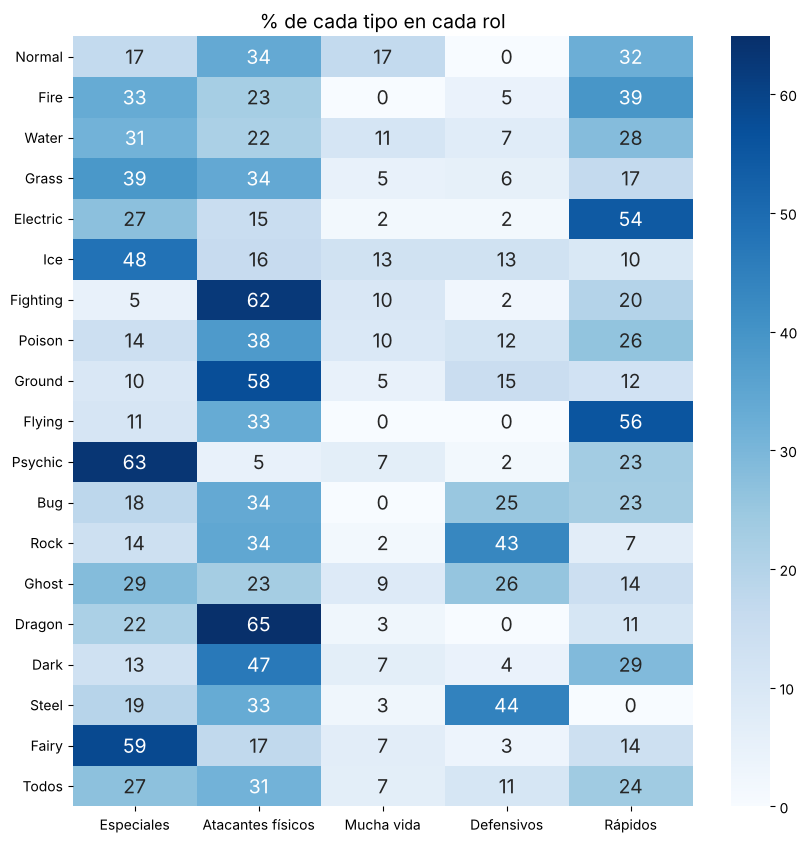

In [23]:
tipos = ['Normal', 'Fire', 'Water', 'Grass', 'Electric', 'Ice', 'Fighting', 'Poison', 'Ground',
         'Flying', 'Psychic', 'Bug', 'Rock', 'Ghost', 'Dragon', 'Dark', 'Steel', 'Fairy'] #Los 18 tipos en el orden oficial del juego

filas = []
for tipo in tipos:
    del_tipo = df[df['Type1'] == tipo]
    filas.append([100 * (del_tipo['Rol'] == rol).sum() / len(del_tipo) for rol in nombres]) #% del tipo que cayó en cada rol

filas.append([100 * (df['Rol'] == rol).sum() / len(df) for rol in nombres]) #Reparto de todos los Pokémon
validacion = pd.DataFrame(filas, columns=nombres, index=tipos + ['Todos'])

plt.figure(figsize=(10, 10))
sns.heatmap(validacion, cmap='Blues', annot=True, fmt='.0f')
plt.yticks(rotation=0) #Nombres de los tipos en horizontal
plt.title('% de cada tipo en cada rol')
plt.show()

<p>Observación: los Pokémon tipo Lucha (Fighting), Dragón (Dragon) y Tierra (Ground) caen sobre todo en Atacantes físicos; Psíquico (Psychic), Hada (Fairy) y Hielo (Ice) en Especiales; Eléctrico (Electric) y Volador (Flying) en Rápidos; y Roca (Rock) y Acero (Steel) caen en Defensivos cuatro veces más que el promedio (43-44% contra 11%). Los Normal son los que más aparecen en Mucha vida (como Snorlax, Chansey y Blissey).</p>
<p>Otros tipos, como Agua (Water), se reparten casi igual que el total: no tienen un rol propio. Volador tiene solo 9 Pokémon con ese tipo principal (casi todos los voladores lo tienen como segundo tipo), así que su porcentaje es menos confiable.</p>

<h1>Visualización</h1>
<p>Con 6 dimensiones no se pueden ver todos los datos en una sola gráfica. Se usa <code>pairplot</code> para ver cada par de stats, con cada Pokémon coloreado según su rol.</p>

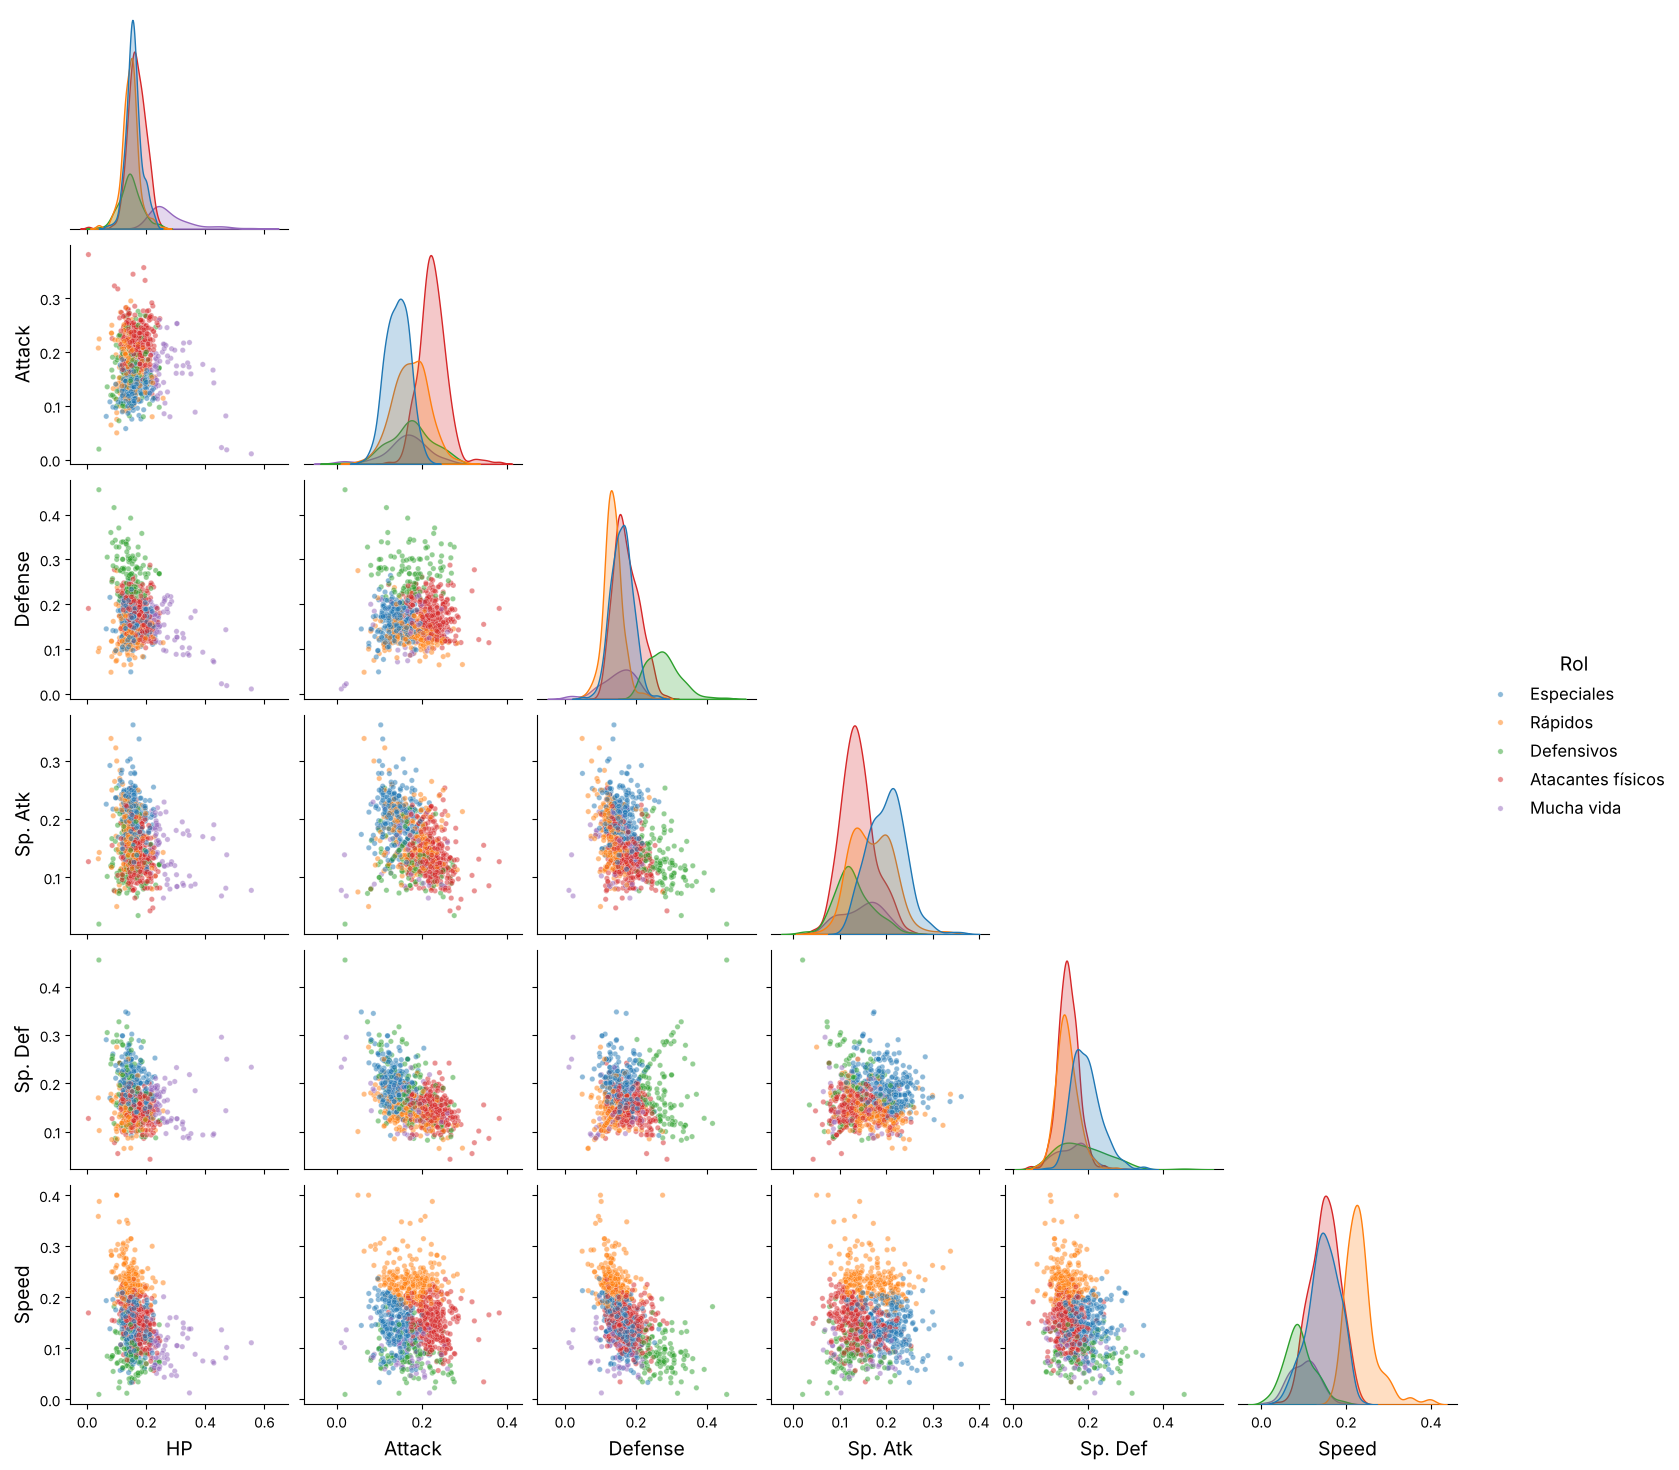

In [24]:
perfil = pd.DataFrame(X, columns=stats)
perfil['Rol'] = df['Rol'].values

sns.pairplot(perfil, hue='Rol', corner=True, plot_kws={'alpha':0.5, 's':15})
plt.show()

<p>Observación: cada rol se separa en la stat que lo define. Por ejemplo, en la columna de Defense los Defensivos quedan a la derecha, y en la de HP los de Mucha vida. En los demás pares los grupos se enciman, porque cada gráfica solo muestra 2 de las 6 dimensiones.</p>

<h1>Conclusiones</h1>
<ul>
  <li>K-means encontró 5 roles solo con el perfil de stats de los 1,025 Pokémon: Atacantes físicos, Especiales, Rápidos, Defensivos y Mucha vida.</li>
  <li>Los roles coinciden con lo que se espera en el juego aunque K-means nunca vio los tipos: Lucha y Dragón son atacantes físicos, Psíquico y Hada especiales, Eléctrico rápidos, y Roca y Acero defensivos.</li>
  <li>Usar el perfil (fracción del total) en lugar de las stats tal cual es lo que permite encontrar roles; con las stats tal cual K-means solo separa débiles contra fuertes.</li>
  <li>Mewtwo, Alakazam y Gengar suelen considerarse atacantes especiales, sin embargo quedaron en Rápidos. Su stat más destacada sí es Sp. Atk, pero también tienen la velocidad muy por arriba del promedio (Alakazam: +10.8 puntos en Sp. Atk y +8.1 en Speed). K-means compara el perfil completo con cada centroide, y el grupo de Especiales se define por Sp. Atk <i>y</i> Sp. Def altas con velocidad por debajo del promedio; como estos tres son muy rápidos y no tan defensivos, quedan más cerca del centroide de Rápidos. En el juego serían "atacantes especiales rápidos", una mezcla de dos roles.</li>
</ul>

<p>Limitaciones: la silueta es baja (~0.2) porque los roles se traslapan y muchos Pokémon son equilibrados; k no tiene una única respuesta (el codo es suave); y K-means asume grupos más o menos redondos y de tamaño parecido, por eso un grupo chico y extremo como "Mucha vida" puede absorber Pokémon que no son tan extremos.</p>